# 📊 Análise Exploratória de Dados (EDA) - Dataset Ransomware

Neste notebook, realizei a Análise Exploratória do dataset `ransom.csv`. O objetivo é compreender a distribuição do conjunto de dados, examinar o balanceamento da variável alvo e identificar comportamentos distintos entre ficheiros Benignos e diferentes categorias/famílias de Malware.

In [16]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Configuração de estilo para os gráficos
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)

# Carregar o dataset a partir de data/raw/
df = pd.read_csv('../data/raw/ransom.csv')

print(f"Dimensão do Dataset: {df.shape[0]} amostras | {df.shape[1]} colunas")
df.head(3)

Dimensão do Dataset: 21752 amostras | 77 colunas


,md5,sha1,file_extension,EntryPoint,PEType,MachineType,magic_number,bytes_on_last_page,pages_in_file,relocations,...,total_procsses,files_malicious,files_suspicious,files_text,files_unknown,dlls_calls,apis,Class,Category,Family
0,d5aa2b2506dd71b65307bb551a6a099d,62f4d55a1bb8396e493d7815dc44febed7161535,exe,0x108ec,PE32+,AMD AMD64,MZ,0x0090,0x0003,0x0000,...,0.0,0.0,0.0,0.0,0.0,6.0,162.0,Benign,Benign,Benign
1,8d1178cec97f96a9ede3efe2f30ef30e,ca40945a4e35d48794a5e13aacf16b8ae1caddeb,exe,0x25cf9c,PE32+,AMD AMD64,MZ,0x0090,0x0003,0x0000,...,93.0,0.0,0.0,0.0,0.0,22.0,778.0,Benign,Benign,Benign
2,c08d7afb7966f452cf5aa9283fe8880a,6f47b50480bea61ae4dfb75c12582990cc5ce770,exe,0x2a7e,PE32,"Intel 386 or later, and compatibles",MZ,0x0090,0x0003,0x0000,...,35.0,0.0,0.0,0.0,0.0,1.0,1.0,Benign,Benign,Benign


## 1. Inspeção Geral e Verificação de Dados Ausentes
Verifiquei a estrutura dos dados, os tipos de colunas e a presença de valores nulos no dataset.

In [17]:
# Informação sobre tipos de dados e valores em falta
print("Contagem de Valores Ausentes por Coluna (Top 10):")
missing_vals = df.isnull().sum()
print(missing_vals[missing_vals > 0].head(10))

if missing_vals.sum() == 0:
    print("\n✅ Excelente: O dataset não possui valores em falta!")

Contagem de Valores Ausentes por Coluna (Top 10):
Series([], dtype: int64)

✅ Excelente: O dataset não possui valores em falta!


## 2. Distribuição das Variáveis Alvo (`Class`, `Category` e `Family`)
Analisei o equilíbrio do dataset ao nível binário (Benigno vs. Malware) e ao nível detalhado por categorias e famílias de malware.

C:\Users\casim\AppData\Local\Temp\ipykernel_10404\451487981.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='Class', palette='Set2', ax=axes[0])
C:\Users\casim\AppData\Local\Temp\ipykernel_10404\451487981.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='Category', order=df['Category'].value_counts().index, palette='crest', ax=axes[1])


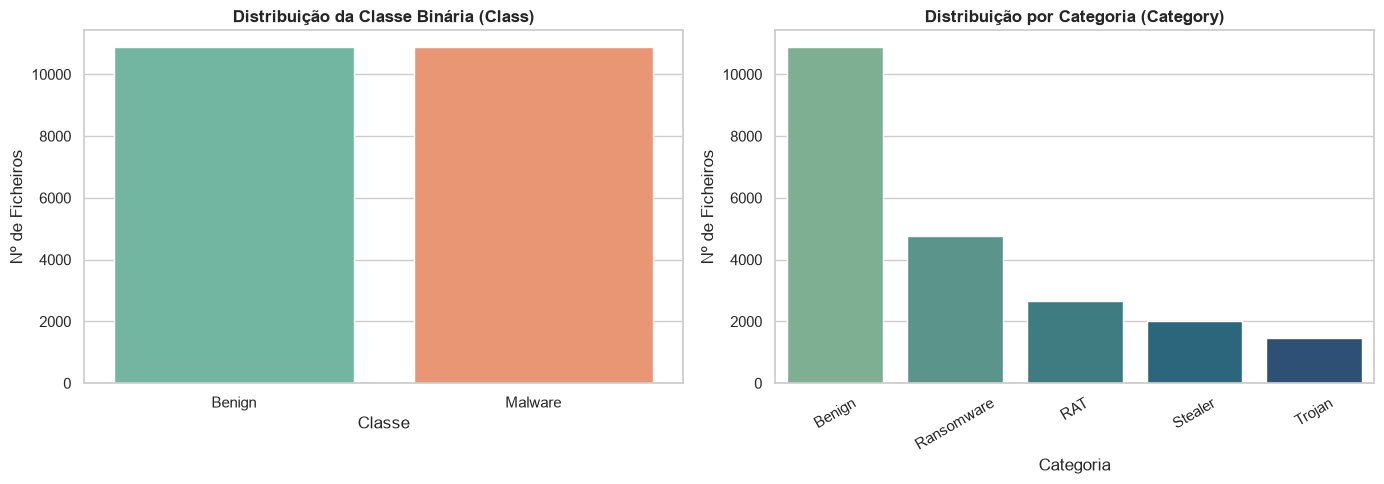

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. Classe Binária
sns.countplot(data=df, x='Class', palette='Set2', ax=axes[0])
axes[0].set_title('Distribuição da Classe Binária (Class)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Classe')
axes[0].set_ylabel('Nº de Ficheiros')

# 2. Categorias de Malware
sns.countplot(data=df, x='Category', order=df['Category'].value_counts().index, palette='crest', ax=axes[1])
axes[1].set_title('Distribuição por Categoria (Category)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Categoria')
axes[1].set_ylabel('Nº de Ficheiros')
axes[1].tick_params(axis='x', rotation=30)

plt.tight_layout()
plt.show()

## 3. Top Famílias de Malware
Identifiquei as principais famílias de malware presentes no dataset (ex.: Phobos, WannaCry, Ryuk, Dharma).

C:\Users\casim\AppData\Local\Temp\ipykernel_10404\77884000.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_families.values, y=top_families.index, palette='Reds_r')


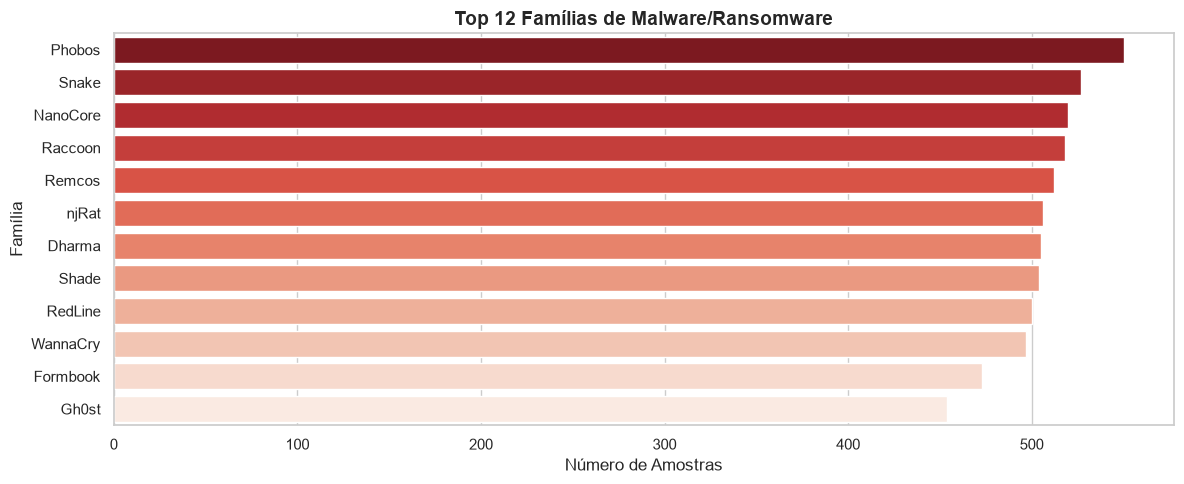

In [19]:
plt.figure(figsize=(12, 5))

top_families = df[df['Family'] != 'Benign']['Family'].value_counts().head(12)
sns.barplot(x=top_families.values, y=top_families.index, palette='Reds_r')

plt.title('Top 12 Famílias de Malware/Ransomware', fontsize=14, fontweight='bold')
plt.xlabel('Número de Amostras')
plt.ylabel('Família')
plt.tight_layout()
plt.show()

## 4. Análise do Comportamento Dinâmico por Categoria
Comparação das médias de atividade do sistema (escrita no registo, ligações de rede, chamadas de API e ficheiros maliciosos) entre ficheiros Benignos e Ransomware.

--- Média de Atividade do Sistema por Categoria ---


,registry_write,network_connections,processes_malicious,files_malicious,apis
Category,,,,,
Benign,5.16,5.01,0.02,0.25,87.33
RAT,44.23,19.18,4.80,3.54,105.17
Ransomware,42.85,72.87,3.30,30.73,117.22
Stealer,34.49,10.19,4.09,9.96,50.01
Trojan,77.07,5.99,1.88,2.34,133.90


C:\Users\casim\AppData\Local\Temp\ipykernel_10404\2025689075.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='Category', y='apis', palette='Set3', ax=axes[0])
C:\Users\casim\AppData\Local\Temp\ipykernel_10404\2025689075.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='Category', y='registry_write', palette='Set3', ax=axes[1])


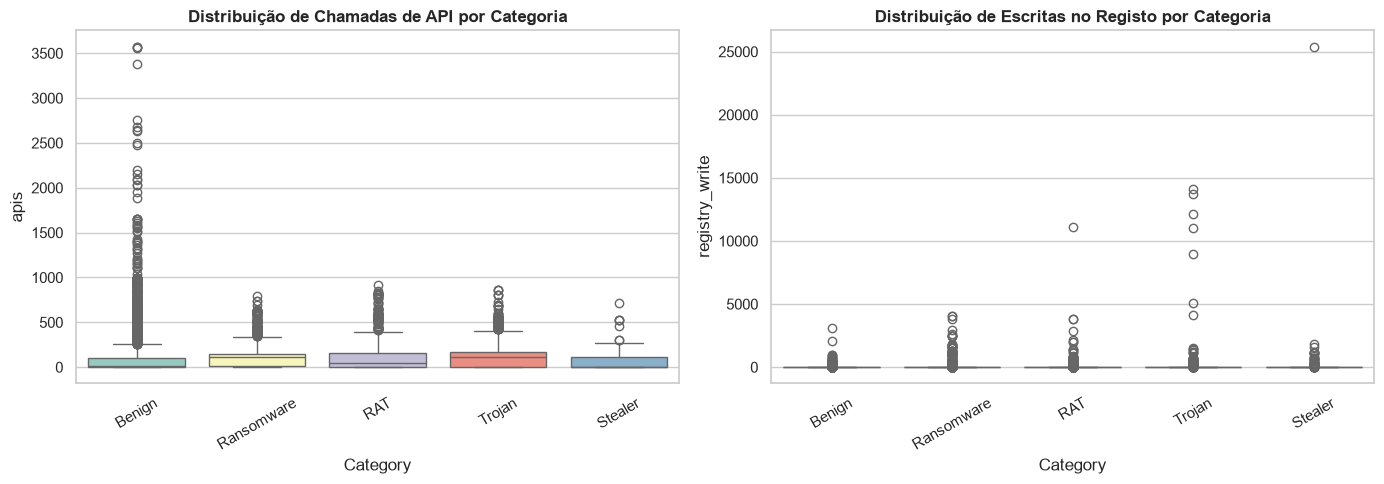

In [20]:
behavioral_cols = ['registry_write', 'network_connections', 'processes_malicious', 'files_malicious', 'apis']

# Tabela resumo das médias comportamentais
resumo_comportamental = df.groupby('Category')[behavioral_cols].mean().round(2)
print("--- Média de Atividade do Sistema por Categoria ---")
display(resumo_comportamental)

# Gráfico comparativo de chamadas de API e Escritas no Registo
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.boxplot(data=df, x='Category', y='apis', palette='Set3', ax=axes[0])
axes[0].set_title('Distribuição de Chamadas de API por Categoria', fontweight='bold')
axes[0].tick_params(axis='x', rotation=30)

sns.boxplot(data=df, x='Category', y='registry_write', palette='Set3', ax=axes[1])
axes[1].set_title('Distribuição de Escritas no Registo por Categoria', fontweight='bold')
axes[1].tick_params(axis='x', rotation=30)

plt.tight_layout()
plt.show()

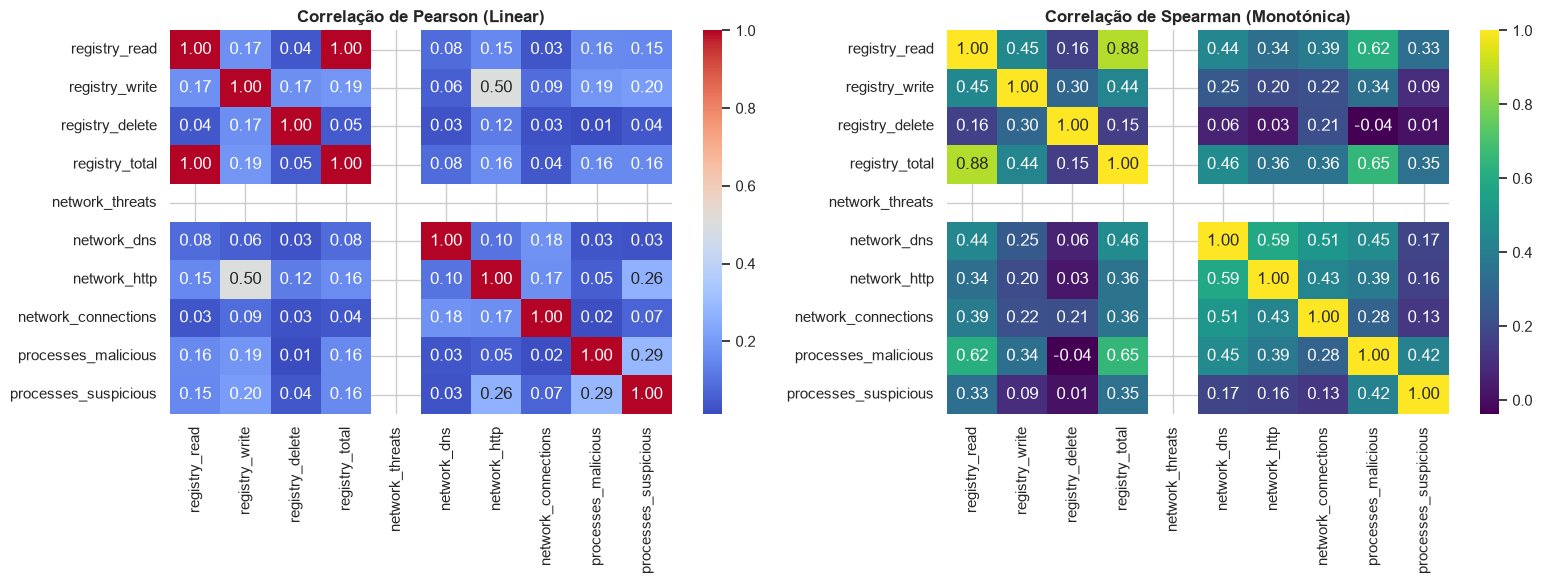

In [21]:
# Célula de Código: Matrizes de Correlação (Pearson vs Spearman)
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

num_cols = df.select_dtypes(include=['float64', 'int64']).columns[:10] # Top 10 atributos numéricos

# Pearson (Relação Linear)
sns.heatmap(df[num_cols].corr(method='pearson'), annot=True, fmt=".2f", cmap="coolwarm", ax=axes[0])
axes[0].set_title("Correlação de Pearson (Linear)", fontweight='bold')

# Spearman (Relação Monotónica)
sns.heatmap(df[num_cols].corr(method='spearman'), annot=True, fmt=".2f", cmap="viridis", ax=axes[1])
axes[1].set_title("Correlação de Spearman (Monotónica)", fontweight='bold')

plt.tight_layout()
plt.show()